# Duelo: Random Forest × SVM — quem vai cancelar o plano?

## O contexto
Você é a pessoa de Machine Learning de uma **operadora de telecomunicações**. Todo mês, uma parte dos clientes
cancela o plano. No mercado, isso se chama **churn**, e custa caro: conquistar um cliente novo sai bem mais caro do que manter um antigo.

O **time de retenção** quer uma lista dos clientes com maior risco de cancelar para ligar para eles **antes** que saiam,
oferecendo desconto ou upgrade.

**Sua missão:** comparar os dois modelos que você aprendeu, **Random Forest** e **SVM**, e recomendar um ao gerente.

**Os dados:** *Telco Customer Churn*, um dos datasets mais conhecidos do Kaggle (publicado pela IBM): 7.043 clientes, 20 informações sobre cada um.


---
## Etapa 0 — Conhecer e limpar os dados

In [64]:
import time
import warnings
warnings.filterwarnings("ignore")   # esconde avisos de métricas do "modelo preguiçoso"
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


| Coluna | Significado |
|---|---|
| `tenure` | há quantos **meses** a pessoa é cliente |
| `Contract` | tipo de contrato: mensal, 1 ano ou 2 anos |
| `MonthlyCharges` / `TotalCharges` | valor da mensalidade / total já pago |
| `InternetService` | tipo de internet: DSL, fibra ótica ou nenhuma |
| `PaymentMethod` | forma de pagamento (cheque eletrônico, cartão, débito automático…) |
| `TechSupport`, `OnlineSecurity`… | serviços adicionais contratados |
| `SeniorCitizen`, `Partner`, `Dependents` | idoso? tem cônjuge? tem dependentes? |
| `Churn` | **o que queremos prever:** cancelou (`Yes`) ou não (`No`) |

**0.1** Quantos clientes cancelaram?

In [65]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

**0.2 Um problema escondido.** A coluna `TotalCharges` deveria ser número, mas veio como **texto**:
11 clientes novos têm um espaço em branco no lugar do valor. O `pd.to_numeric` converte para número;
o parâmetro `errors` diz o que fazer com o que não for número. Queremos que vire **vazio** (`NaN`) para depois remover.


In [66]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valores vazios:", df["TotalCharges"].isna().sum())

df = df.dropna().drop(columns="customerID")     # remove os 11 vazios e o ID (não ajuda a prever)
y = (df.pop("Churn") == "Yes").astype(int)      # 1 = cancelou
X = pd.get_dummies(df, drop_first=True, dtype=int)  # texto → colunas 0/1 (one-hot)
print(f"{X.shape[0]} clientes | {X.shape[1]} colunas | {y.mean():.1%} cancelaram")

Valores vazios: 11
7032 clientes | 30 colunas | 26.6% cancelaram


<details><summary>Travou? Clique para ver uma dica</summary>

A opção que transforma o que não é número em `NaN` é `"coerce"`, com aspas.
</details>

**0.3 A função de avaliação.** Desta vez vamos olhar **mais de uma métrica**:

> **Lembrete de métricas (Unidade II)**
> - **Acurácia:** de todos os clientes, quantos o modelo acertou.
> - **Recall (do churn):** dos clientes que **realmente cancelaram**, quantos o modelo **pegou**. É o que interessa ao time de retenção: cliente que cancela e não foi avisado é cliente perdido.
> - **F1:** equilíbrio entre recall e precisão (dos que o modelo apontou, quantos cancelaram mesmo).
> - **Tempo:** quanto a validação cruzada levou. Em produção, tempo é custo.

In [67]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []

def avaliar(nome, modelo):
    inicio = time.time()
    r = cross_validate(modelo, X, y, cv=cv, scoring=["accuracy", "recall", "f1"])
    segundos = time.time() - inicio
    linha = {"Modelo": nome,
             "Acurácia": r["test_accuracy"].mean(),
             "Recall (churn)": r["test_recall"].mean(),
             "F1": r["test_f1"].mean(),
             "Tempo (s)": segundos}
    resultados.append(linha)
    print(f"{nome:<32} acurácia {linha['Acurácia']:.1%} | recall {linha['Recall (churn)']:.1%} | "
          f"F1 {linha['F1']:.1%} | {segundos:.1f}s")

---
## Etapa 1 — A linha de base: o "modelo preguiçoso"

Antes de qualquer modelo de verdade, sempre se pergunta: **e se eu chutasse a resposta mais comum?**
O `DummyClassifier` faz exatamente isso: diz que **ninguém** vai cancelar.

In [68]:
avaliar("Chute: ninguém cancela", DummyClassifier(strategy="most_frequent"))

Chute: ninguém cancela           acurácia 73.4% | recall 0.0% | F1 0.0% | 0.0s


**1.1 O chute acertou cerca de 73%. Isso é bom? O que o recall de 0% significa para o time de retenção?**

A acurácia de aproximadamente 73% parece boa, mas pode enganar. Como a maioria dos clientes não cancela, o modelo consegue essa porcentagem mesmo prevendo que ninguém vai cancelar. O recall de 0% mostra que ele não conseguiu identificar nenhum cliente que realmente cancelaria, o que prejudica o trabalho da equipe de retenção.

---
## Etapa 2 — Random Forest

> **Lembrete:** muitas árvores diferentes votando. Não precisa escalar os dados.
> `RandomForestClassifier(n_estimators=..., max_depth=..., random_state=42)`

**2.1** Escreva a Random Forest com **300 árvores** e **profundidade máxima 8**.

In [69]:
avaliar("Random Forest", RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42))

Random Forest                    acurácia 80.3% | recall 49.9% | F1 57.4% | 5.8s


<details><summary>Travou? Clique para ver uma dica</summary>

`RandomForestClassifier(n_estimators=300, max_depth=8, random_state=42)`
</details>

---
## Etapa 3 — SVM

> **Lembrete:** o SVM decide por **distância**. Repare nas escalas:
> `tenure` vai de 1 a 72, `TotalCharges` vai até **8.684**, e as colunas do one-hot são 0 ou 1.

**3.1** Rode o SVM **sem** escalar:

In [70]:
avaliar("SVM sem escala", SVC())

SVM sem escala                   acurácia 73.4% | recall 0.0% | F1 0.0% | 4.7s


**3.2 Compare o SVM sem escala com o chute da Etapa 1. O que aconteceu? Por quê?**

O SVM sem escala teve 73,4% de acurácia e recall de 0%, ou seja, ficou praticamente como um modelo que prevê que ninguém vai cancelar. Isso acontece porque a variável TotalCharges tem valores muito maiores que tenure e as colunas com valores 0 e 1. Assim, ela acaba tendo mais influência no cálculo das distâncias. Com o StandardScaler, as variáveis ficam em escalas semelhantes, ajudando o modelo a considerar melhor todas elas.

**3.3** Agora monte o SVM **com escala**, usando um pipeline:

In [71]:
avaliar("SVM com escala", make_pipeline(StandardScaler(), SVC()))

SVM com escala                   acurácia 79.6% | recall 49.0% | F1 56.1% | 3.8s


<details><summary>Travou? Clique para ver uma dica</summary>

Igual à aula de SVM: `make_pipeline(StandardScaler(), SVC())`.
</details>

---
## Etapa 4 — O duelo

In [72]:
pd.DataFrame(resultados).set_index("Modelo").style.format(
    {"Acurácia": "{:.1%}", "Recall (churn)": "{:.1%}", "F1": "{:.1%}", "Tempo (s)": "{:.1f}"})

,Acurácia,Recall (churn),F1,Tempo (s)
Modelo,,,,
Chute: ninguém cancela,73.4%,0.0%,0.0%,0.0
Random Forest,80.3%,49.9%,57.4%,5.8
SVM sem escala,73.4%,0.0%,0.0%,4.7
SVM com escala,79.6%,49.0%,56.1%,3.8


**4.1 Quem venceu em acurácia? E em recall? A diferença entre os dois é grande?**

A Random Forest teve um resultado um pouco melhor que o SVM, com 80,3% de acurácia contra 79,6%. No recall, também ficou na frente, com 50% contra 49%. Porém, como a diferença é pequena, os dois modelos apresentaram resultados bem parecidos.

**4.2 Os dois pegam cerca de metade dos clientes que cancelam. Por que isso é um problema para o time de retenção?**

Mesmo com uma acurácia próxima de 80%, o modelo ainda deixa passar muitos clientes que vão cancelar. Com um recall de aproximadamente 50%, ele identifica apenas metade desses clientes. Isso dificulta o trabalho da equipe de retenção, que poderia entrar em contato com esses clientes antes que eles cancelassem.

---
## Etapa 5 — Uma decisão de negócio

Como só ~27% dos clientes cancelam, os modelos "preferem" dizer que o cliente fica. O parâmetro **`class_weight="balanced"`**
dá mais peso aos erros na classe rara: errar um cliente que cancela passa a custar mais caro durante o treino.
Os dois modelos aceitam esse parâmetro.

**5.1** Complete os dois modelos com `class_weight="balanced"`:

In [73]:
avaliar("Random Forest balanceada",
        RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42))
avaliar("SVM balanceado",
        make_pipeline(StandardScaler(), SVC(class_weight="balanced")))

Random Forest balanceada         acurácia 76.3% | recall 77.1% | F1 63.3% | 5.7s
SVM balanceado                   acurácia 74.5% | recall 78.0% | F1 61.9% | 4.7s


<details><summary>Travou? Clique para ver uma dica</summary>

É o mesmo texto nos dois, com aspas: `"balanced"`.
</details>

In [74]:
pd.DataFrame(resultados).set_index("Modelo").style.format(
    {"Acurácia": "{:.1%}", "Recall (churn)": "{:.1%}", "F1": "{:.1%}", "Tempo (s)": "{:.1f}"})

,Acurácia,Recall (churn),F1,Tempo (s)
Modelo,,,,
Chute: ninguém cancela,73.4%,0.0%,0.0%,0.0
Random Forest,80.3%,49.9%,57.4%,5.8
SVM sem escala,73.4%,0.0%,0.0%,4.7
SVM com escala,79.6%,49.0%,56.1%,3.8
Random Forest balanceada,76.3%,77.1%,63.3%,5.7
SVM balanceado,74.5%,78.0%,61.9%,4.7


**5.2 O que aconteceu com a acurácia e com o recall ao balancear? O que se ganhou e o que se perdeu?**

Depois do balanceamento, a acurácia diminuiu nos dois modelos, enquanto o recall aumentou para cerca de 77% a 78%. Isso significa que eles passaram a identificar mais clientes com chance de cancelar. O F1 também melhorou, mostrando um equilíbrio melhor entre precisão e recall. Por outro lado, aumentaram os falsos positivos, ou seja, alguns clientes que não cancelariam também passaram a ser identificados como risco.

**5.3 Para o time de retenção, o que custa mais caro: ligar para um cliente que não ia sair, ou não ligar para um que vai sair? Qual versão você entregaria?**
Na minha opinião, perder um cliente pode gerar um prejuízo maior do que fazer uma ligação desnecessária, já que conquistar novos clientes costuma custar mais do que manter os atuais. Por isso, eu escolheria a versão balanceada, pois ela consegue identificar mais clientes que podem cancelar, mesmo que também indique alguns clientes que não cancelariam.

---
## Etapa 6 — Por que os clientes cancelam?

O gerente não quer só a lista: quer saber **o que fazer** para reduzir o churn.
A Random Forest diz quais colunas ela mais usou. O SVM com kernel RBF **não** oferece isso de forma direta.

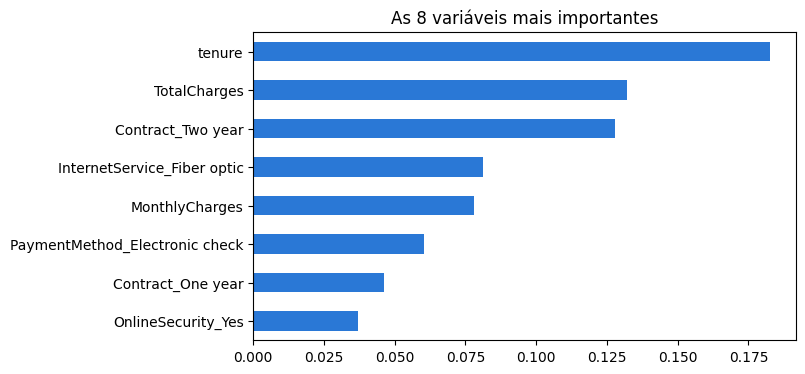

In [75]:
rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42).fit(X, y)
importancia = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(8)
importancia.plot.barh(color="#2a78d6", figsize=(7, 4), title="As 8 variáveis mais importantes")
plt.show()

6.1 Cite três variáveis do topo e uma ação que a empresa poderia tomar a partir delas.
As variáveis mais importantes foram tenure, TotalCharges e Contract_Two year, seguidas por InternetService_Fiber optic, MonthlyCharges e PaymentMethod_Electronic check.
Com base nisso, algumas ações que a empresa poderia adotar são:
* Tenure: como o tempo de permanência do cliente é importante, a empresa pode acompanhar melhor os clientes novos e oferecer suporte nos primeiros meses.
* Contrato: oferecer vantagens ou descontos para clientes que desejam mudar para contratos de um ou dois anos.
* Fibra óptica: verificar se existem reclamações relacionadas à qualidade da conexão ou ao preço do serviço.
* Cobrança mensal: analisar se os valores cobrados estão influenciando a decisão de cancelamento.

<details><summary>Extra para quem terminou: SVM linear</summary>

Com muitas colunas 0/1, às vezes uma fronteira reta basta. Teste:

```python
avaliar("SVM linear", make_pipeline(StandardScaler(), SVC(kernel="linear")))
```
Ele bate o SVM rbf? E a Random Forest?
</details>

---
## Sua recomendação ao gerente

In [76]:
pd.DataFrame(resultados).set_index("Modelo").sort_values("Recall (churn)", ascending=False).style.format(
    {"Acurácia": "{:.1%}", "Recall (churn)": "{:.1%}", "F1": "{:.1%}", "Tempo (s)": "{:.1f}"})

,Acurácia,Recall (churn),F1,Tempo (s)
Modelo,,,,
SVM balanceado,74.5%,78.0%,61.9%,4.7
Random Forest balanceada,76.3%,77.1%,63.3%,5.7
Random Forest,80.3%,49.9%,57.4%,5.8
SVM com escala,79.6%,49.0%,56.1%,3.8
Chute: ninguém cancela,73.4%,0.0%,0.0%,0.0
SVM sem escala,73.4%,0.0%,0.0%,4.7


**Em até 4 frases, para alguém que não é da área: qual modelo você recomenda, com qual ajuste, e por quê?**
Eu recomendaria a Random Forest com balanceamento de classes, pois ela consegue identificar cerca de 77% dos clientes que podem cancelar, contra aproximadamente 50% sem o ajuste. Apesar de gerar mais falsos positivos, considero que vale a pena entrar em contato com alguns clientes que permaneceriam, se isso ajudar a evitar a perda de outros. Além disso, a Random Forest permite analisar quais variáveis mais influenciam as previsões, como o tempo de permanência e o tipo de contrato. Dessa forma, a equipe de retenção pode agir de forma mais direcionada para tentar manter os clientes
